<a href="https://colab.research.google.com/github/Annah998936/CSE547-Machine-Learning-Big-Data/blob/main/CSE_547_Big_Data_Debugging_Tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSE547 - Colab Extra
## Big Data Debugging Tutorial

This Colab is partially adapted from Jay Mody's blog post ["Computing Distance Matrices with NumPy"](https://jaykmody.com/blog/distance-matrices-with-numpy/).

### Setup

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import time
%matplotlib inline

from keras.datasets import mnist

Load the [MNIST](https://www.tensorflow.org/datasets/catalog/mnist) dataset from "keras.datasets" module.

In [ ]:
#loading the dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()

#printing the shapes of the vectors
print('X_train: ' + str(X_train.shape))
print('y_train: ' + str(y_train.shape))
print('X_test:  '  + str(X_test.shape))
print('y_test:  '  + str(y_test.shape))

11490434/11490434 [==============================] - 0s 0us/step
X_train: (60000, 28, 28)
y_train: (60000,)
X_test:  (10000, 28, 28)
y_test:  (10000,)


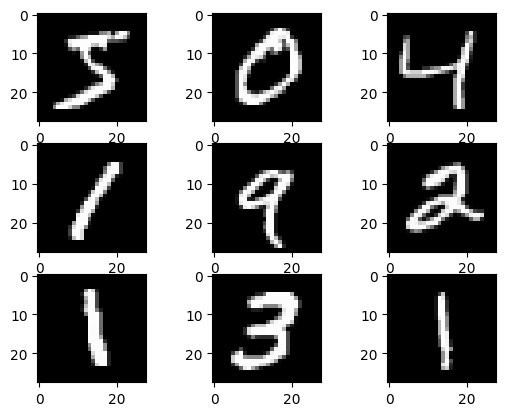

In [ ]:
for i in range(9):
    plt.subplot(330 + 1 + i)
    plt.imshow(X_train[i], cmap=plt.get_cmap('gray'))
plt.show()

### Background

A distance matrix $D$ is a square matrix that captures the pairwise distances between a set of vectors. In particular,
$D_{ij}=dist(v_i,v_j)$ for a pair of points $v_i,v_j$. When $v_i,v_j$ are vectors in the Euclidean space $\mathbb{R}^d$, the most commonly used distance is the Euclidean distance
$$dist(v_i,v_j) = \|v_i-v_j \|_2.$$

### Motivating Example: k-Nearest Neighbors

[$k$ Nearest Neighbors](https://cs231n.github.io/classification/#k---nearest-neighbor-classifier) (kNN) is a machine learning classification algorithm that utilizes distance matrices under the hood. The idea is simple: we can predict the class of any given data point by looking at the classes of the nearest neighboring labelled data points. Whichever class is most common within the neighbors is the class that we predict for the data point.

How do you determine which labelled points are the "nearest"? In most cases of machine learning tasks, we represent each data point as a vector, and the proximity between points can be characterized through their euclidean distance.

In the actual applications, there are $n$ labelled data points (training data) and $m$ unlabelled data points (test data, for which we would like to classify). The data points are represented as vectors of dimensionality $d$. To implement the kNN classifier, we need to compute the distances between all labelled-unlabelled pairs. These distances can be stored in an $(m,n)$ matrix $D$, where $D_{ij}$ represents the distance between the $i$-th unlabelled point and the $j$-th labelled point. If we represent our labelled data points by the $(n,d)$ matrix $Y$, and our unlabelled data points by the $(m,d)$ matrix $X$, the distance matrix can be formulated as:
$$D_{ij}=\sqrt{\sum_{k=1}^d \left(X_{ik}-Y_{jk}\right)^2}.$$

The distance computation is the essence of the kNN algorithm, and we will showcase how to compute the pairwise distance efficiently with relatively big datasets.

## Taking subsets of the data for algorithm development

---

Before diving into the implementation of euclidean distance, we want to subset the data to more quickly code up the logic for the euclidean distance. This speeds up development and debugging as we are on only a subset fraction of the data

We subset  2000 instances of the training set and the 100 instances of the test set to shorten the running time. The three-loop versions take relatively more time to execute, but the subsequent code runs much faster. We will explore 3 subsampling strategies:
* Subsampling the first samples
* Random subsampling
* Stratified subsampling

In [ ]:
N1 = 2000 # subset size of training data
N2 = 200 # subset size of testing data

In [ ]:
from sklearn.model_selection import train_test_split


def first_subset(X, y, N):
    # we take the first N elements of all data
    X_subset = X[:N]
    y_subset = y[:N]

    return X_subset, y_subset

def random_subset(X, y, N):
    # we randomly subsample the data
    indices = np.random.choice(np.arange(len(X)), N)
    X_subset = X[indices]
    y_subset = y[indices]

    return X_subset, y_subset

def stratified_subset(X, y, N):
    # we perform a stratified subsample of the data using sklearn's train_test_split function
    _, indices = train_test_split(np.arange(len(X)), test_size=N, stratify=y) # we stratify according to the labels
    X_subset = X[indices]
    y_subset = y[indices]

    return X_subset, y_subset

def class_distribution(y):
    # returns the class distribution of a given vector y.
    unique, counts = np.unique(y, return_counts=True)
    return np.round(counts / sum(counts), 2)

In [ ]:
np.random.seed(777)

# of all 3 sampling strategies, the only one that produces an identical label distribution
# to that of the original dataset is stratified sampling.

print("original data class distribution:", end="\t\t"),
print(class_distribution(y_train))

print("first-N subsample class distribution:", end="\t\t"),
print(class_distribution(first_subset(X_train, y_train, N1)[1]))

print("random subsample class distribution:", end="\t\t"),
print(class_distribution(random_subset(X_train, y_train, N1)[1]))

print("stratified subsample class distribution:", end="\t"),
print(class_distribution(stratified_subset(X_train, y_train, N1)[1]))

# Therefore, to speedily debug an implementation for correctness,
# (e.g. to ensure your implementation is correct)
# it is recommended to use stratified subsamples of the original data

# However, if you're speedily debugging your code for soundness
# (e.g. to ensure your code runs smoothly)
# you may use any form of data subsampling

original data class distribution:		[0.1  0.11 0.1  0.1  0.1  0.09 0.1  0.1  0.1  0.1 ]
first-N subsample class distribution:		[0.1  0.11 0.1  0.1  0.11 0.09 0.1  0.11 0.09 0.1 ]
random subsample class distribution:		[0.09 0.11 0.11 0.1  0.09 0.09 0.1  0.1  0.11 0.1 ]
stratified subsample class distribution:	[0.1  0.11 0.1  0.1  0.1  0.09 0.1  0.1  0.1  0.1 ]


In [ ]:
# Reshape and subset the data for computing pairwise distance
# we don't need labels to compute pairwise distance, only for stratified subsampling

# X_train1 - shape (n, d)
# y_train1 - shape (n, )

#a = (m,n,d)
# a.reshape(m, -1) -> (m, n*d)
# a.reshape(-1, d) -> (m*n, d)
X_train1, y_train1 = stratified_subset(X_train, y_train, N1)
X_train1 = X_train1.flatten().reshape(X_train1.shape[0],-1).astype(np.int64)

# X_test1 - shape (m, d)
# y_test1 - shape (m, )
X_test1, y_test1 = stratified_subset(X_test, y_test, N2)
X_test1 = X_test1.flatten().reshape(X_test1.shape[0],-1).astype(np.int64)

m = X_test1.shape[0]   # number of test points
n = X_train1.shape[0]   # number of training points
d = X_train1.shape[1]   # number of features

### Three Loops

The following chunk may take more than 5 minutes to execute. Be aware!!

In [ ]:
start = time.time()

D3 = np.zeros((m, n)) # distance matrix (m, n)
# D3 = np.empty((m, n))

for i in range(m):
    for j in range(n):
        val = 0
        for k in range(d):
            val += (X_test1[i,k] - X_train1[j,k]) ** 2
        D3[i,j] = np.sqrt(val)

three_loop_time = time.time() - start

print("The three loop version took "+str(three_loop_time)+" seconds.\n")
D3

The three loop version took 246.2528052330017 seconds.



array([[3112.10009479, 3074.03610909, 2544.63022854, ..., 3370.6658096 ,
        3016.95707626, 2758.88292611],
       [2960.88128772, 2899.14866814, 3207.43105927, ..., 3182.36845761,
        2891.77125651, 3442.28644944],
       [2897.99930987, 2601.62084094, 2855.07442985, ..., 2919.26309195,
        2476.11813127, 2373.64361268],
       ...,
       [2849.89420856, 2559.3659371 , 3389.10799474, ..., 2600.29267583,
        3124.69774538, 2652.01941924],
       [2570.77867581, 2271.13099578, 3114.25898088, ..., 2970.73559914,
        2486.0197103 , 2599.2435438 ],
       [2940.35406031, 2564.52237268, 2293.05211454, ..., 2776.87792314,
        2526.8064825 , 1596.28005062]])

While this works, it is quite inefficient and does not take advantage of numpy's efficient vectorized operations.

### Two Loops

#### Sometimes, you may find it useful to debug your big data code. However, notebooks don't come with built-in interactive debugging tools, and running algorithms in the cloud (e.g. training machine learning models) does not lend itself to local IDE debuggers. We will use PDB to code a faster euclidean distance algorithm with two loops instead of three. This will allow you to interrupt the flow of the program, and try to speedup the innermost loop in an interactive terminal-like prompt. Always remember to type q(uit) when you're done with PDB!

In [ ]:
# same code as before
import pdb

start = time.time()
D2 = np.zeros((m, n)) # distance matrix (m, n)

for i in range(m):
    for j in range(n):
        # val = 0
        # for k in range(d):
        #   val += (X_test1[i,k] - X_train1[j,k]) ** 2

        # the innermost loop can be vectorized if we subtract and square elements
        # in X_test1 and X_test1, and then take the sum
        val = np.sum((X_test1[i] - X_train1[j]) ** 2)

        # pdb.set_trace() # sets the breakpoint <-- uncomment this line and vectorize the innermost loop. Compare your result to val.
        D2[i,j] = np.sqrt(val)

two_loop_time = time.time() - start
print("The two loop version took "+str(two_loop_time)+" seconds.\n")
D2

The two loop version took 5.428727626800537 seconds.



array([[3112.10009479, 3074.03610909, 2544.63022854, ..., 3370.6658096 ,
        3016.95707626, 2758.88292611],
       [2960.88128772, 2899.14866814, 3207.43105927, ..., 3182.36845761,
        2891.77125651, 3442.28644944],
       [2897.99930987, 2601.62084094, 2855.07442985, ..., 2919.26309195,
        2476.11813127, 2373.64361268],
       ...,
       [2849.89420856, 2559.3659371 , 3389.10799474, ..., 2600.29267583,
        3124.69774538, 2652.01941924],
       [2570.77867581, 2271.13099578, 3114.25898088, ..., 2970.73559914,
        2486.0197103 , 2599.2435438 ],
       [2940.35406031, 2564.52237268, 2293.05211454, ..., 2776.87792314,
        2526.8064825 , 1596.28005062]])

We did see the improvement in elaspe time, but we can do better.

### One Loop

In [ ]:
start = time.time()

D1 = np.zeros((m, n)) # distance matrix (m, n)

for i in range(m):
    D1[i, :] = np.sqrt(np.sum((X_test1[i] - X_train1) ** 2, axis=1))

one_loop_time = time.time() - start
print("The one loop version took "+str(one_loop_time)+" seconds.\n")
D1

The one loop version took 2.9937853813171387 seconds.



array([[3112.10009479, 3074.03610909, 2544.63022854, ..., 3370.6658096 ,
        3016.95707626, 2758.88292611],
       [2960.88128772, 2899.14866814, 3207.43105927, ..., 3182.36845761,
        2891.77125651, 3442.28644944],
       [2897.99930987, 2601.62084094, 2855.07442985, ..., 2919.26309195,
        2476.11813127, 2373.64361268],
       ...,
       [2849.89420856, 2559.3659371 , 3389.10799474, ..., 2600.29267583,
        3124.69774538, 2652.01941924],
       [2570.77867581, 2271.13099578, 3114.25898088, ..., 2970.73559914,
        2486.0197103 , 2599.2435438 ],
       [2940.35406031, 2564.52237268, 2293.05211454, ..., 2776.87792314,
        2526.8064825 , 1596.28005062]])

The above computation leverages the [broadcasting rule](https://numpy.org/doc/stable/user/basics.broadcasting.html) in Numpy array so that one loop is sufficient.

### No Loops?!

We can do even better and only use vector/matrix operations, no loops needed. Here is the magic:
\begin{align*}
D_{ij} &= \sqrt{\sum_{k=1}^d \left(X_{ik}-Y_{jk}\right)^2}\\
&= \sqrt{\sum_{k=1}^d X_{ik}^2 - 2\sum_{k=1}^d X_{ik}Y_{ik} + \sum_{k=1}^d Y_{ik}^2}\\
&=\sqrt{\langle X_i, X_i\rangle -2\langle X_i,Y_j\rangle + \langle Y_j, Y_j\rangle}.
\end{align*}

Notice, for all combinations of $i,j$, the middle term $-2\langle X_i,Y_j\rangle$ is unique, but the left term $\langle X_i, X_i\rangle$ and right term $\langle Y_j, Y_j\rangle$ inside the squared root are repeated. Imagine fixing either $i$ or $j$ and iterate the other variables, we will see that $\langle X_i, X_i\rangle$ shows up $j$ times and $\langle Y_j, Y_j\rangle$ shows up $i$ times. So, our challenge is to figure out how to compute all possible $\langle X_i, X_i\rangle$, $\langle X_i,Y_j\rangle$, and $\langle Y_j, Y_j\rangle$, and then add them together in the right way. All of these can be done without using for loops.

In [ ]:
start = time.time()
# This has the same affect as taking the dot product of each row with itself
# X_test1 - shape (m, k)
# X_test1**2 = X_test1*X_test1

# x2 = np.sum(X_test1**2, axis=1) # shape of (m, )
# y2 = np.sum(X_train1**2, axis=1) # shape of (n, )

# We can compute all x_i * y_j and store it in a matrix at xy[i][j] by
# taking the matrix multiplication between X and X_train transpose
# X_test1 - (m, k); X_train1.T - (k, n)
# xy = np.matmul(X_test1, X_train1.T) # shape of (m, n)

x2 = np.einsum("mk,mk->m", X_test1, X_test1)
y2 = np.einsum("nk,nk->n", X_train1, X_train1)
xy = np.einsum("mk,nk->mn",X_test1, X_train1)

# Each row in xy needs to be added with x2[i]
# each column of xy needs to be added with y2[j]
# to get everything to play well, we'll need to reshape
# x2 from (m) -> (m, 1), numpy will handle the rest of the broadcasting for us
# see: https://numpy.org/doc/stable/user/basics.broadcasting.html
x2 = x2.reshape(-1, 1)

# shapes here are (m, 1), (m, n), (n) which will result in an (m, n) array
D0 = np.sqrt(x2 - 2*xy + y2)

no_loop_time = time.time() - start
print("The no loop version took "+str(no_loop_time)+" seconds.\n")
D0

The no loop version took 0.2962381839752197 seconds.



array([[3112.10009479, 3074.03610909, 2544.63022854, ..., 3370.6658096 ,
        3016.95707626, 2758.88292611],
       [2960.88128772, 2899.14866814, 3207.43105927, ..., 3182.36845761,
        2891.77125651, 3442.28644944],
       [2897.99930987, 2601.62084094, 2855.07442985, ..., 2919.26309195,
        2476.11813127, 2373.64361268],
       ...,
       [2849.89420856, 2559.3659371 , 3389.10799474, ..., 2600.29267583,
        3124.69774538, 2652.01941924],
       [2570.77867581, 2271.13099578, 3114.25898088, ..., 2970.73559914,
        2486.0197103 , 2599.2435438 ],
       [2940.35406031, 2564.52237268, 2293.05211454, ..., 2776.87792314,
        2526.8064825 , 1596.28005062]])

In [ ]:
(D0 == D1).all()
np.allclose(D0, D1)

True

Let us now perform k-means classification on the test data and see how well we are doing. Since all the distance matrices we previously computed have the same values, we will use D0. Our first step is to sort, for each point, the neighbors in increasing order of distance:

In [ ]:
sorted_neigh = D0.argsort(axis=1)
sorted_neigh

array([[ 160, 1310, 1293, ..., 1939, 1869,   43],
       [1539, 1436,  145, ..., 1612,  327, 1563],
       [1417, 1045, 1905, ...,  327, 1054, 1416],
       ...,
       [1257, 1813, 1957, ..., 1437, 1655, 1280],
       [ 872, 1487, 1073, ...,  780,  327,  808],
       [ 561, 1281, 1819, ..., 1869, 1054, 1416]])

Let's first visualize the 10 closest neighbors for 10 random test points:

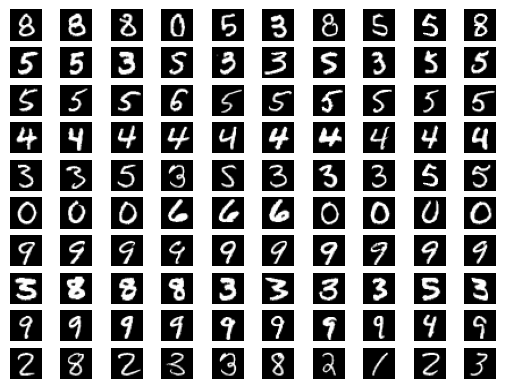

In [ ]:
for i, test_pt in enumerate(np.random.choice(m, size=10, replace=False)):
  for j, close_pt in enumerate(sorted_neigh[test_pt, :10]):

    ax = plt.subplot(10, 10, 1 + i * 10 + j)
    ax.set_axis_off()
    ax.imshow(X_train1[close_pt].reshape(28, 28), cmap=plt.get_cmap('gray'))

plt.show()


Let's write our prediction function. First, for each test point we will select the closest k points(i.e. the first k columns in the closest neighbors matrix will have the indicies of the k closest neighbors). Then we select the labels of the closest neighbors for the training data and vote to see which digit appears the most among these k neighbors. That will be our prediction. In code:

In [ ]:
def predict(k):

  top_k_neigh = sorted_neigh[:, :k]
  top_k_labels = y_train1[top_k_neigh]
  top_k_counts = np.apply_along_axis(np.bincount, axis=1, arr=top_k_labels, minlength=10)

  return top_k_counts.argmax(axis=1)

def test_acc(pred):
  return np.sum(pred == y_test1)/y_test1.shape[0]

Let's test our predictor for different values of k and see how well we're doing.

For 1 neighbors we obtain: 0.9 accuracy
For 2 neighbors we obtain: 0.905 accuracy
For 3 neighbors we obtain: 0.88 accuracy
For 4 neighbors we obtain: 0.885 accuracy
For 5 neighbors we obtain: 0.885 accuracy
For 10 neighbors we obtain: 0.845 accuracy
For 20 neighbors we obtain: 0.84 accuracy
For 50 neighbors we obtain: 0.8 accuracy
For 100 neighbors we obtain: 0.78 accuracy


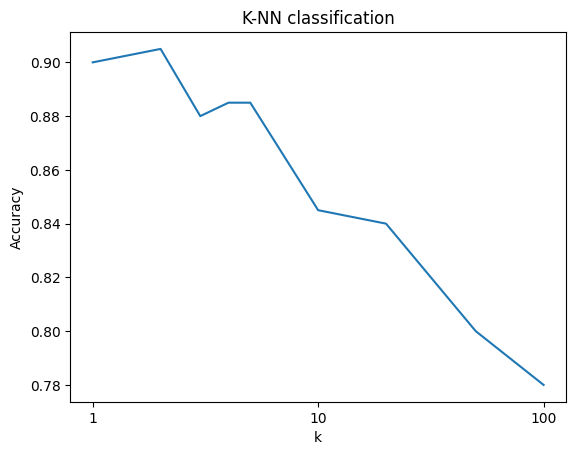

In [ ]:
ks = [1, 2, 3, 4, 5, 10, 20, 50, 100]
test_accs = [test_acc(predict(k)) for k in ks]

for k, acc in zip(ks, test_accs):
  print("For", k, "neighbors we obtain:", acc, "accuracy")

plt.plot(ks, test_accs)

plt.title("K-NN classification")

ax = plt.gca()

ax.set_ylabel("Accuracy")
ax.set_xlabel("k")

ax.set_xscale("log")

ax.set_xticks([], minor=True)
ax.xaxis.set_major_formatter(ticker.ScalarFormatter())

plt.show()
